In [1]:
import warnings
warnings.filterwarnings('ignore')
import os
import scanpy as sc
import seaborn as sns
import cell2location
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cell2location.models import RegressionModel

In [2]:
in_dir = '../../results/02_10x_visium/01_filter_data'
out_dir = '../../results/03_kidney_atlas/09_run_cell2location'

os.makedirs(out_dir, exist_ok=True)

In [3]:
adata = sc.read_h5ad(f'../../results/03_kidney_atlas/08_merge_celltypes/adata.h5ad')

In [4]:
adata

AnnData object with n_obs × n_vars = 200338 × 29732
    obs: 'library', 'nCount_RNA', 'nFeature_RNA', 'percent.er', 'percent.mt', 'degen.score', 'aEpi.score', 'aStr.score', 'cyc.score', 'matrisome.score', 'collagen.score', 'glycoprotein.score', 'proteoglycan.score', 'S.Score', 'G2M.Score', 'Phase', 'experiment', 'experiment.short', 'specimen', 'condition.long', 'condition.l1', 'condition.l2', 'condition.l3', 'patient', 'region.l1', 'region.l2', 'percent.cortex', 'percent.medulla', 'sex', 'race', 'tissue_type', 'assay', 'location', 'laterality', 'snDrop_predicted_subclass', 'snDrop_prediction_score', 'pagoda_k50_infomap', 'pagoda_k100_infomap', 'pagoda_k200_infomap', 'pagoda_k500_infomap', 'clusters', 'subclass.full', 'subclass.l3', 'subclass.l2', 'subclass.l1', 'state.l2', 'state.l1', 'class', 'structure', 'cell_type'
    var: 'genes'
    uns: 'cell_type_colors', 'condition.l3_colors', 'laterality_colors', 'location_colors', 'patient_colors', 'structure_colors', 'subclass.l1_colors', '

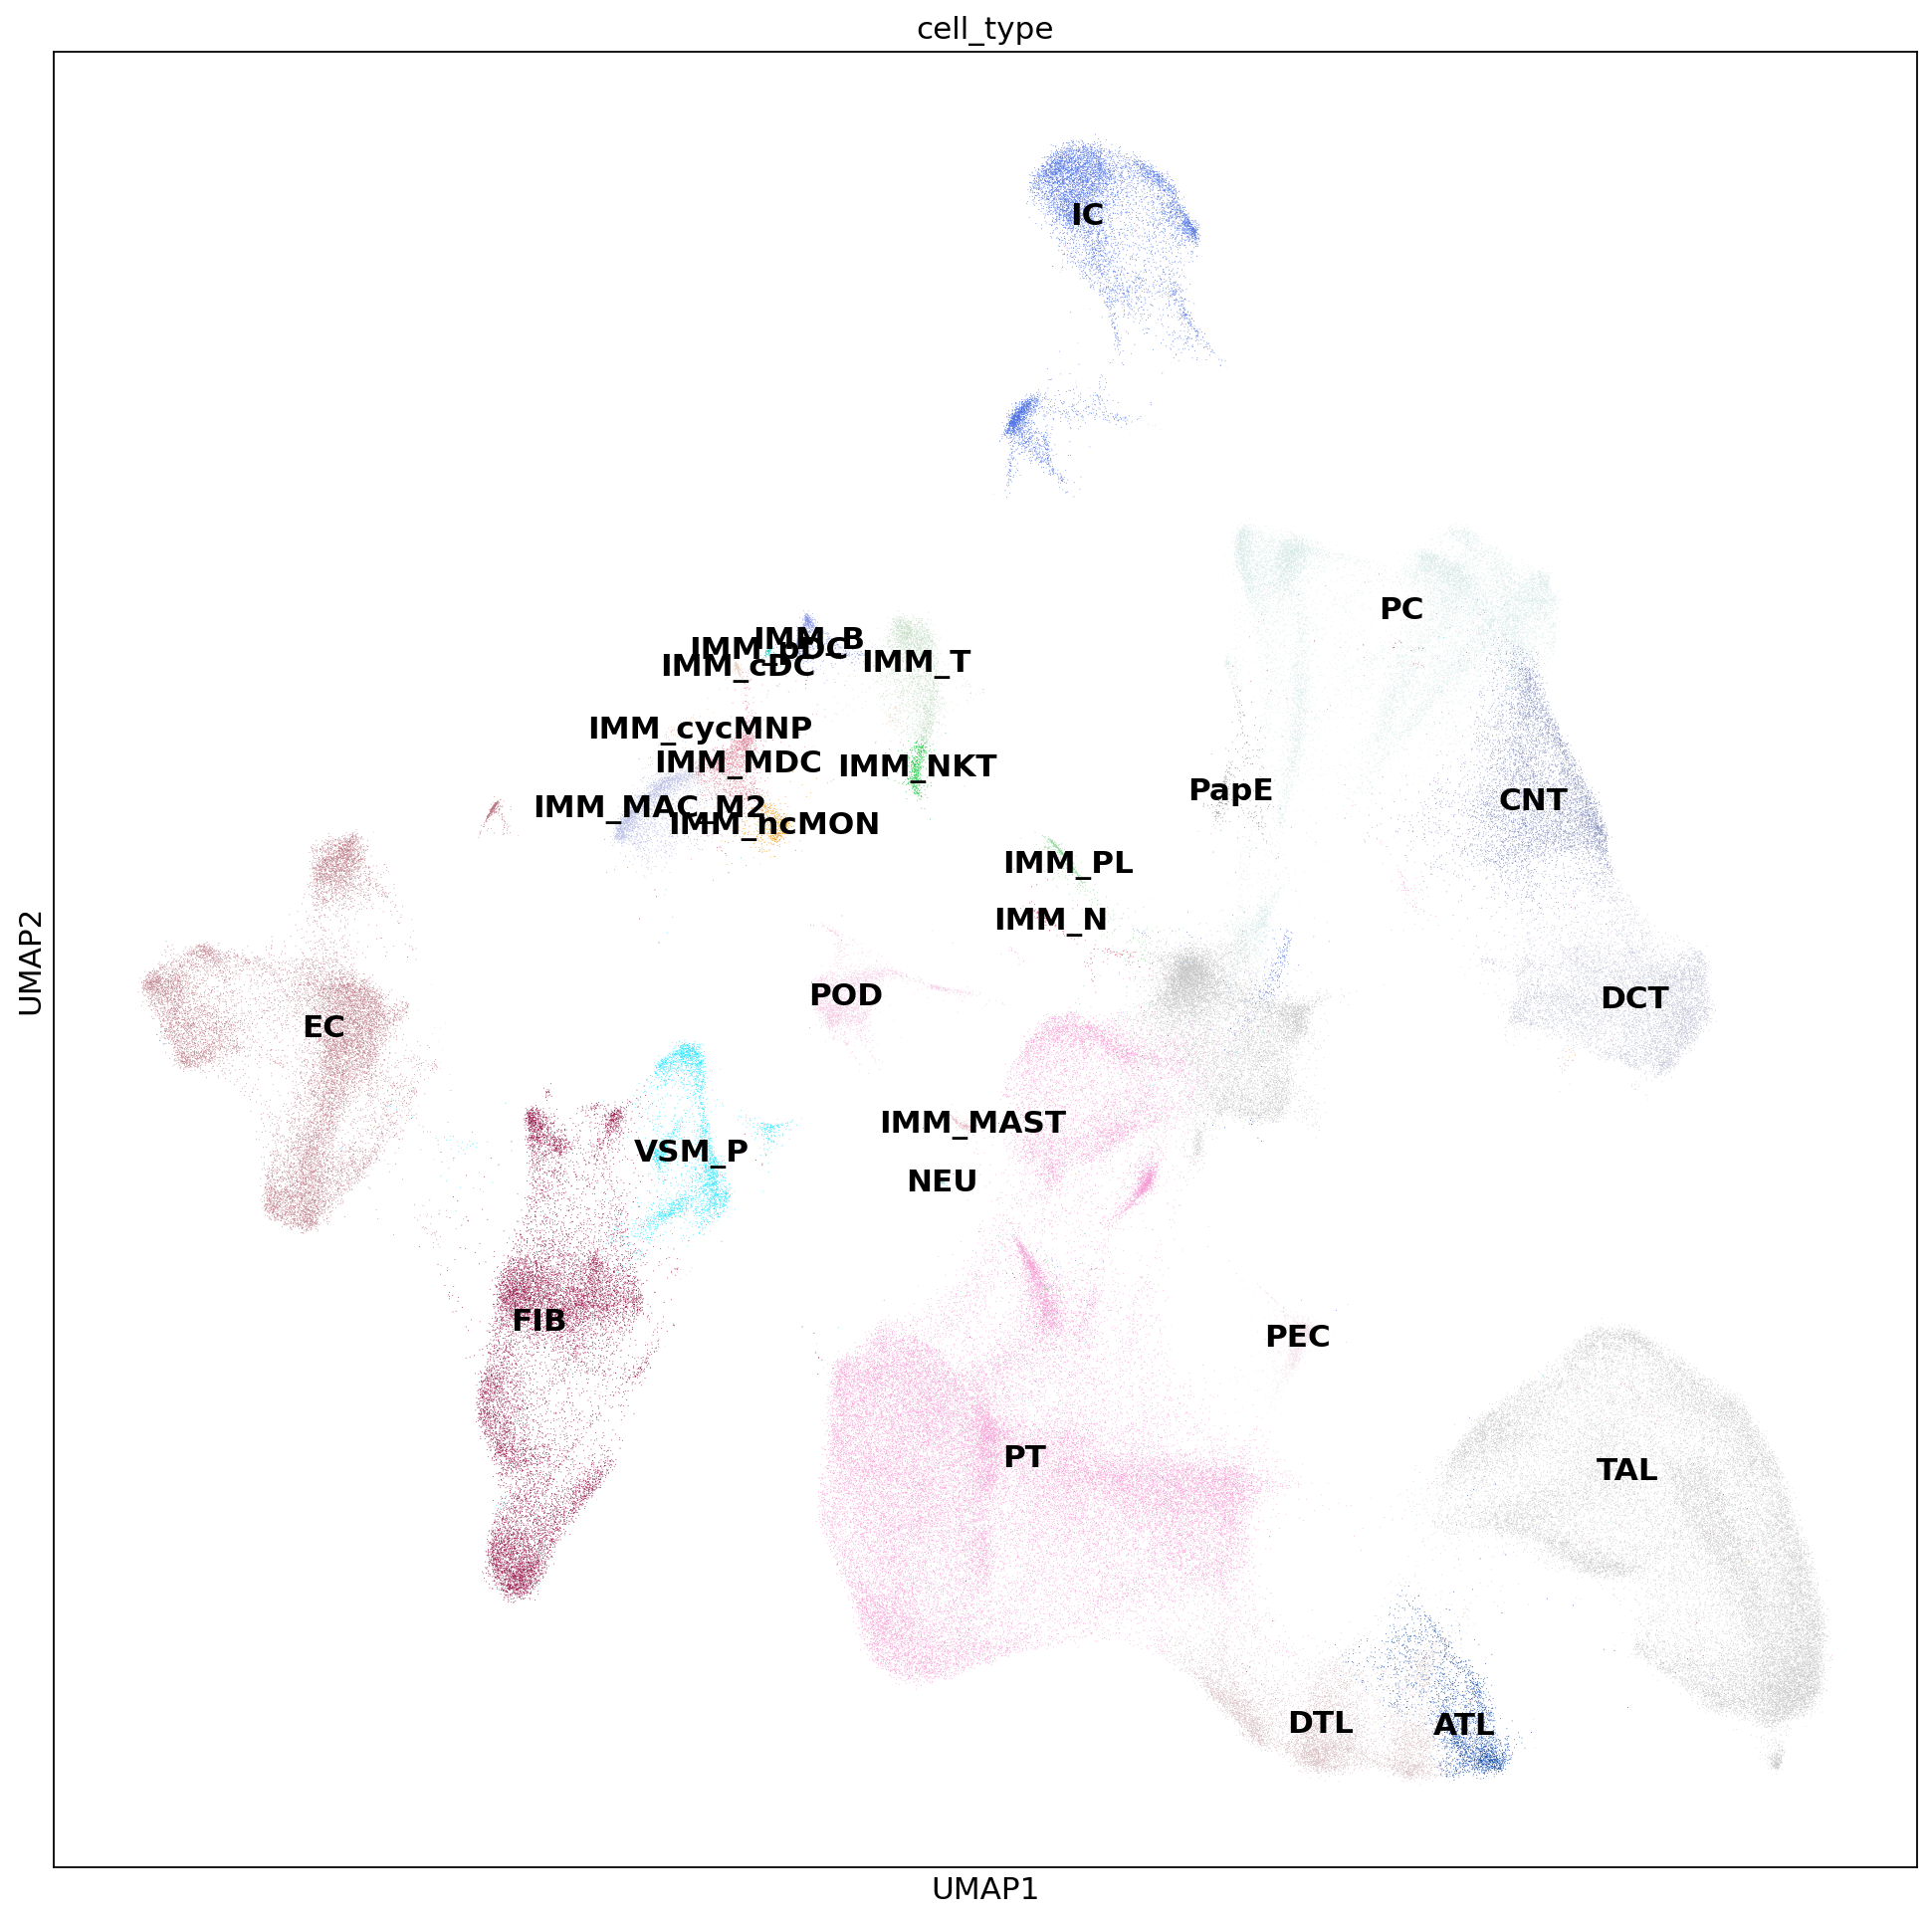

In [5]:
sc.set_figure_params(figsize=(15, 15))
sc.pl.umap(adata, color=['cell_type'], legend_loc='on data')

In [6]:
sc.pp.calculate_qc_metrics(adata, inplace=True)

In [7]:
# filter genes
sc.pp.filter_genes(adata, min_cells=int(0.01 * adata.n_obs))  # keep genes expressed in at least 5% of cells

In [8]:
adata.layers['counts'] = adata.X.copy()

In [9]:
# get markers for each cell type
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

sc.tl.rank_genes_groups(
    adata,
    groupby='cell_type',   # the categorical variable
    method='wilcoxon',     # 't-test', 't-test_overestim_var', or 'wilcoxon'
    key_added='rank_genes_cell_type'  # the name of the new column in adata.uns
)

# Convert to a pandas DataFrame
df_markers = sc.get.rank_genes_groups_df(adata, None, key='rank_genes_cell_type')  # all groups
# Keep top 50 per cell type
df_markers = (
    df_markers.groupby('group', group_keys=False)
    .apply(lambda x: x.nlargest(100, 'logfoldchanges'))
)

In [11]:
adata.X = adata.layers['counts'].copy()

adata_ref = adata[:, df_markers['names'].unique()].copy()

RegressionModel.setup_anndata(adata=adata_ref, labels_key='cell_type',
                              batch_key='patient',
                              categorical_covariate_keys=['library'])
    
mod = RegressionModel(adata_ref)

# view anndata_setup as a sanity check
mod.view_anndata_setup()

mod.train(max_epochs=250)

# In this section, we export the estimated cell abundance (summary of the posterior distribution).
adata_ref = mod.export_posterior(
    adata_ref, 
    sample_kwargs={'num_samples': 1000, 'batch_size': 2500}
)

# Save model
mod.save(f"{out_dir}", overwrite=True)

# export estimated expression in each cluster
if 'means_per_cluster_mu_fg' in adata_ref.varm.keys():
    df = adata_ref.varm['means_per_cluster_mu_fg'][[f'means_per_cluster_mu_fg_{i}'
                                        for i in adata_ref.uns['mod']['factor_names']]].copy()
else:
    df = adata_ref.var[[f'means_per_cluster_mu_fg_{i}'
                                        for i in adata_ref.uns['mod']['factor_names']]].copy()
df.columns = adata_ref.uns['mod']['factor_names']

Anndata setup with scvi-tools version 1.3.3.

Setup via `RegressionModel.setup_anndata` with arguments:

{
│   'layer': None,
│   'batch_key': 'patient',
│   'labels_key': 'cell_type',
│   'categorical_covariate_keys': ['library'],
│   'continuous_covariate_keys': None
}

         Summary Statistics          
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓
┃     Summary Stat Key     ┃ Value  ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩
│         n_batch          │   36   │
│         n_cells          │ 200338 │
│ n_extra_categorical_covs │   1    │
│ n_extra_continuous_covs  │   0    │
│         n_labels         │   27   │
│          n_vars          │  1753  │
└──────────────────────────┴────────┘

                             Data Registry                             
┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃      Registry Key      ┃            scvi-tools Location             ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│           X            │                  adata.X                   │
│         batch          │          adata.obs['_scvi_batch']          │
│ extra_categorical_covs │ adata.obsm['_scvi_extra_categorical_covs'] │
│         ind_x          │           adata.obs['_indices']            │
│         labels         │         adata.obs['_scvi_labels']          │
└────────────────────────┴────────────────────────────────────────────┘

...

Epoch 250/250: 100%|██████████| 250/250 [39:39<00:00, 10.46s/it, v_num=1, elbo_train=9.77e+7]

`Trainer.fit` stopped: `max_epochs=250` reached.


Epoch 250/250: 100%|██████████| 250/250 [39:39<00:00,  9.52s/it, v_num=1, elbo_train=9.77e+7]

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.



Sampling global variables, sample: 100%|██████████| 999/999 [00:06<00:00, 143.54it/s]


In [12]:
df.to_csv(f'{out_dir}/marker_genes.csv')

In [13]:
df = pd.read_csv(f'{out_dir}/marker_genes.csv', index_col=0)

In [14]:
df.head()

,ATL,CNT,DCT,DTL,EC,FIB,IC,IMM_B,IMM_MAC_M2,IMM_MAST,...,IMM_ncMON,IMM_pDC,NEU,PC,PEC,POD,PT,PapE,TAL,VSM_P
SH3GL3,5.459073,0.009875,0.006475,0.521706,0.000314,0.002612,0.009636,0.001725,0.005213,0.006913,...,0.002427,0.025055,0.042435,0.034943,0.006318,0.002331,0.002197,0.009125,0.019990,0.000626
ABCA4,2.330945,0.110838,0.021616,0.522143,0.012581,0.009811,0.016810,0.002505,0.006108,0.006411,...,0.005587,0.037593,0.021779,0.191420,0.027840,0.028547,0.002456,0.020748,0.075740,0.002465
BCAS1,1.432225,0.024211,0.014602,0.451313,0.002829,0.002104,0.011456,0.031920,0.002077,0.012885,...,0.003160,0.020656,0.021295,0.072137,0.011927,0.004558,0.004155,2.046253,0.102313,0.001653
FGF18,0.220233,0.000952,0.003138,0.043803,0.022953,0.003993,0.002127,0.001712,0.003998,0.004241,...,0.010422,0.022022,0.022710,0.008667,0.001458,0.001911,0.000177,0.017752,0.003110,0.004289
CNTD2,0.619629,0.000992,0.003457,0.195683,0.000306,0.000601,0.002096,0.001603,0.001119,0.005366,...,0.005597,0.024401,0.024412,0.002877,0.001144,0.010951,0.003512,0.007857,0.037118,0.000824


Text(294.30176767676767, 0.5, 'Genes')

<Figure size 800x640 with 0 Axes>

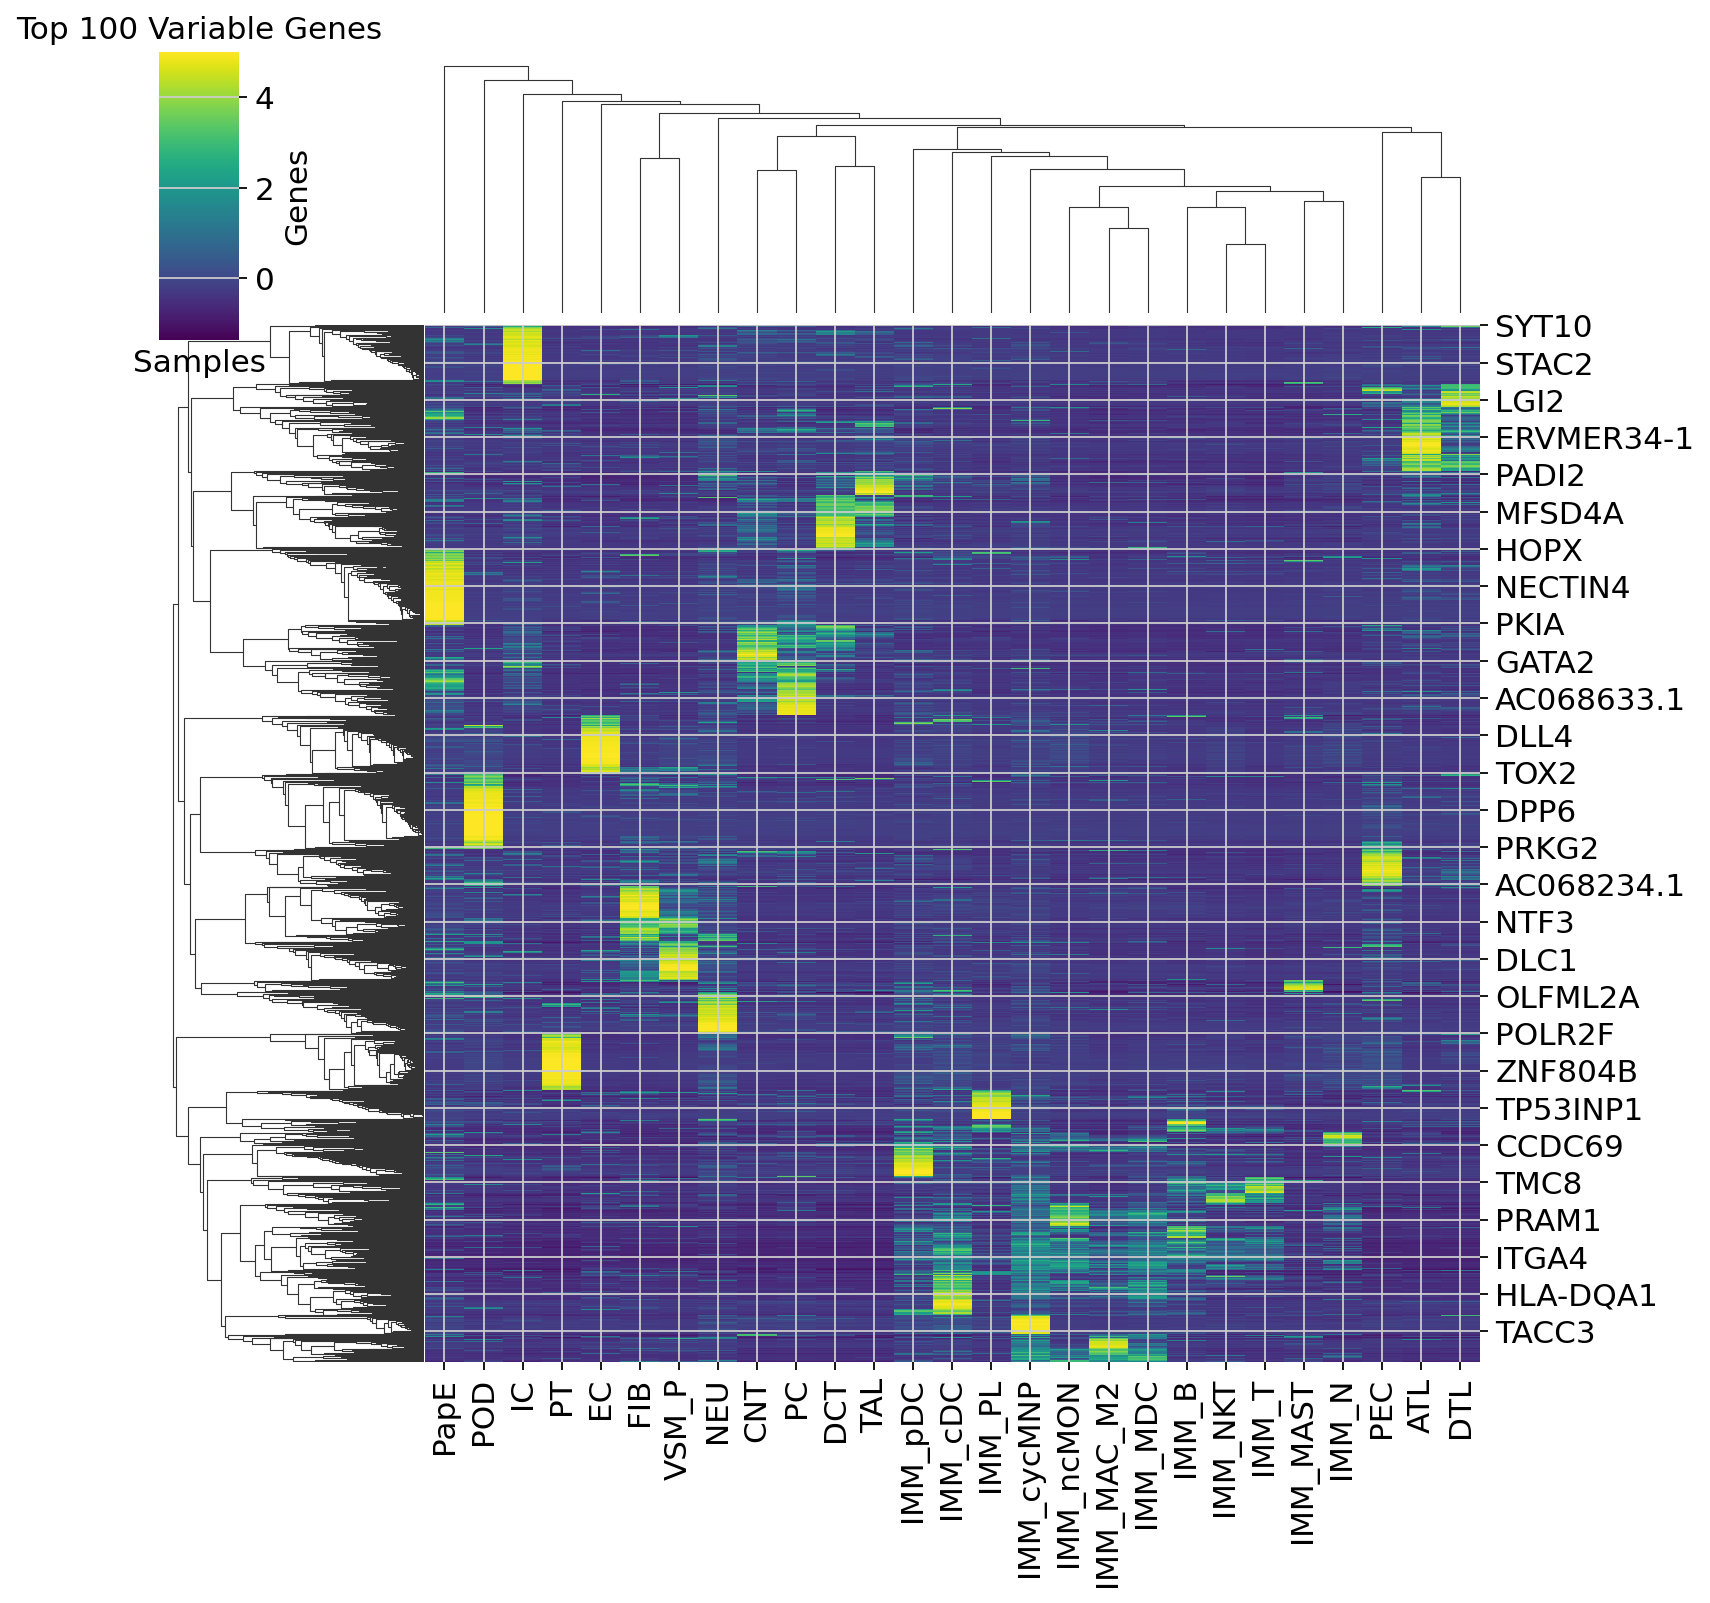

In [15]:
# first normalize the data for better visualization z-score normalization
df = (df - df.mean(axis=1).values[:, None]) / df.std(axis=1).values[:, None]

plt.figure(figsize=(10, 8))
sns.clustermap(df, cmap='viridis')
plt.title('Top 100 Variable Genes')
plt.xlabel('Samples')
plt.ylabel('Genes')

In [ ]:
sample_list = ['15837', '15852', '16512', '21022', '8262', 
               'B23-03794-5', 'B23-05785-7-1', 'B23-05785-7-2', 
               'X1842', 'X1845', 'X1899', 'X1912']

for sample in sample_list:
    adata_vis = sc.read_h5ad(f'{in_dir}/{sample}.h5ad')
    
    adata_vis.var_names_make_unique()

    # find mitochondria-encoded (MT) genes
    adata_vis.var['MT_gene'] = [gene.startswith('MT-') for gene in adata_vis.var_names]

    # remove MT genes for spatial mapping (keeping their counts in the object)
    adata_vis.obsm['MT'] = adata_vis[:, adata_vis.var['MT_gene'].values].X.toarray()
    adata_vis = adata_vis[:, ~adata_vis.var['MT_gene'].values]
    
    df_avg_exp = pd.read_csv(f'{out_dir}/marker_genes.csv', index_col=0)
    df_avg_exp.columns = [col.replace('/', '_') for col in df_avg_exp.columns]
    df_avg_exp.columns = [col.replace('-', '_') for col in df_avg_exp.columns]
        
    # find shared genes and subset both anndata and reference signatures
    intersect = np.intersect1d(adata_vis.var_names, df_avg_exp.index)
    adata_vis = adata_vis[:, intersect].copy()
    inf_aver_subset = df_avg_exp.loc[intersect, :].copy()

    # prepare anndata for cell2location model
    cell2location.models.Cell2location.setup_anndata(adata=adata_vis)
        
    # create and train the model
    mod = cell2location.models.Cell2location(
            adata_vis, 
            cell_state_df=inf_aver_subset,
            N_cells_per_location=30, # number of cells per spot
            detection_alpha=20
    )
        
    mod.train(max_epochs=30000, batch_size=None, train_size=1)
        
    # In this section, we export the estimated cell abundance (summary of the posterior distribution).
    adata_vis = mod.export_posterior(
            adata_vis, sample_kwargs={'num_samples': 1000, 'batch_size': mod.adata.n_obs}
    )
        
    adata_vis.obs[adata_vis.uns['mod']['factor_names']] = adata_vis.obsm['q05_cell_abundance_w_sf']
    adata_vis.write(f'{out_dir}/{sample}.h5ad')

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


Epoch 96/30000:   0%|          | 95/30000 [00:05<27:09, 18.35it/s, v_num=1, elbo_train=6.03e+5]